In [36]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

file_name = "simulation-proba-train.txt"
data = pd.read_csv(file_name, sep=" ", header=None, names=["indiv", "time", "proba"])

In [37]:
file_name = "../output/simulated.txt"
simulated = pd.read_csv(file_name, sep=" ", index_col=["index"])

In [38]:
simulations = {}
for indiv in data["indiv"].unique():
    df = data[data["indiv"] == indiv]
    simulations[int(indiv)] = df.drop(columns=["indiv"])

'\nfor n, _ in enumerate(simulations) :\n    ax[n].fill_betweenx(([simulated.at[first_case, "onset_time"], 0), simulated["study_period"].max()])\n'

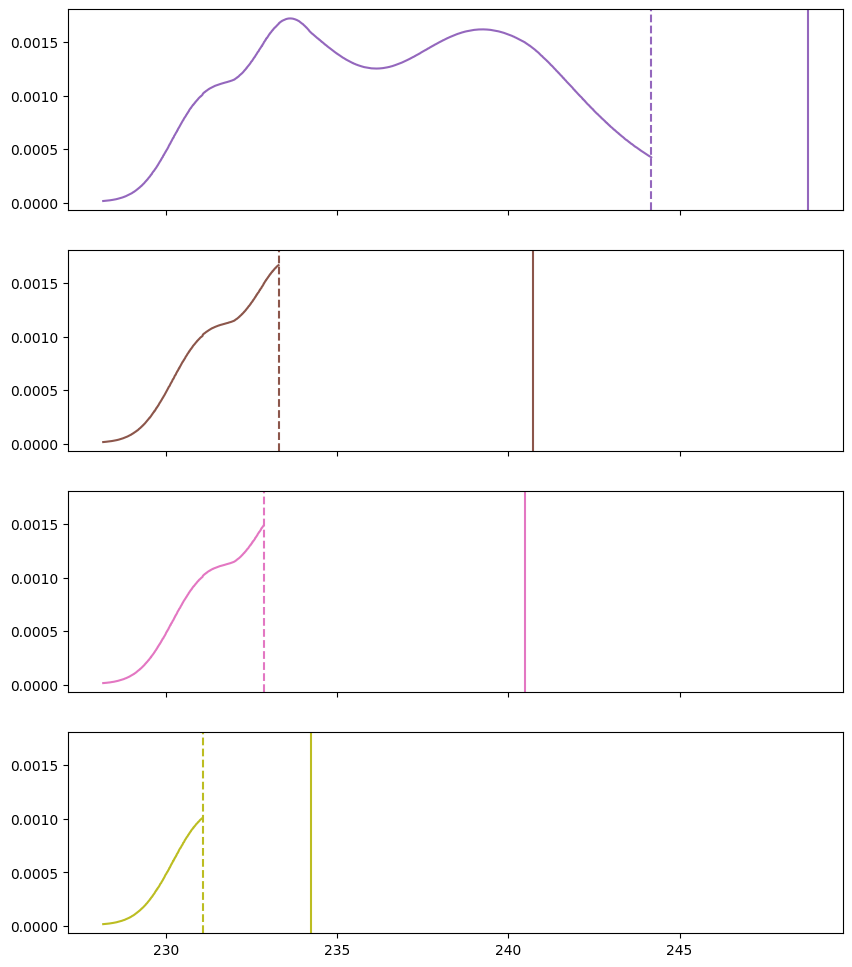

In [39]:
nrows = len(simulations)
fig, ax = plt.subplots(nrows = nrows, figsize=(10, nrows*3), sharex=True, sharey=True)

first_case = list(set(simulated.index) - set(data["indiv"].unique()))[0]

colors = ['#9467bd', '#8c564b', '#e377c2', '#bcbd22', '#17becf']

for n, i in enumerate(simulations) :
    ax[n].plot(simulations[i]["time"], simulations[i]["proba"], color=colors[n])
    onset_time = simulated.at[i, "onset_time"]
    incub_period = simulated.at[i, "incub_period"]
    ax[n].axvline(x=onset_time-incub_period, ls="--", color=colors[n])
    ax[n].axvline(x=onset_time, ls="-", color=colors[n])
    #ax[n].set_ylim([0, data["proba"].max()])


'''
for n, _ in enumerate(simulations) :
    ax[n].fill_betweenx(([simulated.at[first_case, "onset_time"], 0), simulated["study_period"].max()])
'''

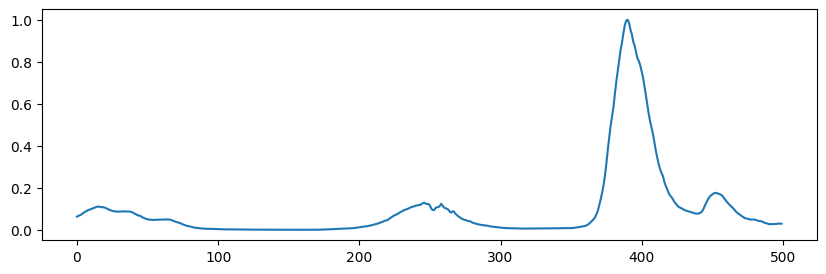

In [40]:
fig, ax = plt.subplots(nrows = 1, figsize=(10, 3))

file_name = "../data/community_infection.txt"
community = pd.read_csv(file_name, sep=" ", header=None, names=["day", "inst", "cumul"], index_col=["day"])
ax.plot(community.index, community["inst"])